# Gradient Boosting
## Regression

In this Jupyter Notebook, we will go over the typical programming progress of regression in Gradient Boosting.

We are using the Carseats-1.csv file from the class modules.

### Step 1: Preparations

Prepare pandas and numPy to read our data as a pandas data frame.

In [49]:
import pandas as pd
import numpy as np 
df = pd.read_csv('Carseats-1.csv', usecols=[1,6,10,11])
df

,Sales,Price,Urban,US
0,9.50,120,Yes,Yes
1,11.22,83,Yes,Yes
2,10.06,80,Yes,Yes
3,7.40,97,Yes,Yes
4,4.15,128,Yes,No
...,...,...,...,...
395,12.57,128,Yes,Yes
396,6.14,120,No,Yes
397,7.41,159,Yes,Yes
398,5.94,95,Yes,Yes


### Encoding our Urban and US labels to numerical values

In [50]:
# Making mapping dict
# Turning Urban category into numerical values
urban_mapping = {label: idx for idx, label in enumerate(np.unique(df['Urban']))}
urban_mapping

{'No': 0, 'Yes': 1}

In [51]:
# Repeat for US
us_mapping = {label: idx for idx, label in enumerate(np.unique(df['US']))}
us_mapping

{'No': 0, 'Yes': 1}

In [52]:
df['Urban'] = df['Urban'].map(urban_mapping)
df['US'] = df['US'].map(urban_mapping)
df

,Sales,Price,Urban,US
0,9.50,120,1,1
1,11.22,83,1,1
2,10.06,80,1,1
3,7.40,97,1,1
4,4.15,128,1,0
...,...,...,...,...
395,12.57,128,1,1
396,6.14,120,0,1
397,7.41,159,1,1
398,5.94,95,1,1


### Assigning our data's features to X, and our target variable, "Sales," to y

In [53]:
X = df.loc[:,['Price','Urban','US']]
y = df['Sales']
display(X)
display(y)

,Price,Urban,US
0,120,1,1
1,83,1,1
2,80,1,1
3,97,1,1
4,128,1,0
...,...,...,...
395,128,1,1
396,120,0,1
397,159,1,1
398,95,1,1


0       9.50
1      11.22
2      10.06
3       7.40
4       4.15
       ...  
395    12.57
396     6.14
397     7.41
398     5.94
399     9.71
Name: Sales, Length: 400, dtype: float64

### Step 2: Assigning our hyper parameters and the train test split

To begin assigning our train test split, we first import the GradientBoostingRegressor, RandomizedSearchCV (for Cross Validation), train_test_split, and mean_squared_error elements to our program.

We then create a dict of our hyper parameters:

#### n_estimators:
The number of decision trees used

#### max_depth:
The maximum number of levels for each decision tree

#### learning_rate:
The amount of improvement the next tree increments with

#### random_state:
Normally, GradientBoostingRegressor automatically creates random numbers to compare itself with. Using a fixed random state assures that we can tune our model properly to a given state, and then release it later to see how accurate the model is for other states.

In [54]:
import time
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# The base hyperparameters for our gradient boosting regression.
# By default, our loss = squared_error.
# This means that the loss function we use in place in the Gradient Boosting algorithm
# is the squared error function.
params = dict(n_estimators=1000, max_depth=3, learning_rate=0.1, random_state=42)#, max_features = 5)

X_train, X_val, y_train, y_val = train_test_split(X, y, 
                                                    test_size = 0.2, 
                                                    random_state = 42)

### Step 3: Preventative Overfitting Measures: Cross Validation

This is the process for Cross Validation.

We create a list of parameters for RandomizedSearchCV to dissect and put a Gradient Boosting Regressor model into it.

RandomizedSearchCV also has hyper parameters of its own. In this case:
estimator is our Gradient Boosting Regressor model
param_distributions our parameters for our Gradient Boosting Regressor
n_iter is 10
our cross folds (cv) are 5
scoring is neg_root_mean_squared_error to use our metric, Root Mean Squared Error, to see our model's final loss.
and n_jobs=-1 to use all processors to run this part of the program.

We then save the best parameters and best model from our RandomizedSearchCV variable

In [ ]:
param_dist = {
    'learning_rate': np.arange(0.1, 0.2, 0.01), 
    'n_estimators': [10, 100, 250, 400],  
    'max_depth': [3, 5, 7, 9],  
}

gb_model = GradientBoostingRegressor()

random_search = RandomizedSearchCV(estimator=gb_model, param_distributions=param_dist, n_iter=10, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)

random_search.fit(X_train, y_train)

best_params = random_search.best_params_
best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_val)

rmse_best = mean_squared_error(y_val, y_pred_best) ** (1/2)

print("Best Parameters:", best_params)
print(f"Best Model RMSE: {rmse_best}")

Best Parameters: {'n_estimators': 10, 'max_depth': 5, 'learning_rate': np.float64(0.11)}
Best Model RMSE: 3.0786296253198904


### Step 3.5: Preventative Overfitting Measures: Early Stopping

Here is where we begin performing Early Stopping. In a way, early stopping finds a stopping point for us and gives us what is potentially the best model accuracy we can get by stopping the amount of decision trees used before our error gets out of hand with more decision trees.

To prepare, we use the same parameters as last time and add validation_fraction and n_iter_no_change to 10. The greater these numbers are, the farther they go into following decision trees after error grows back before they stop.

In [56]:
gbm_full = GradientBoostingRegressor(**params)
gbm_early_stopping = GradientBoostingRegressor(
    **params,

    # ! These are our early stopping parameters ! #
    validation_fraction=0.1,
    n_iter_no_change=10,
)


start_time = time.time()
gbm_full.fit(X_train, y_train)
pred_y_full = gbm_full.predict(X_val)
training_time_full = time.time() - start_time
n_estimators_full = gbm_full.n_estimators_

start_time = time.time()
gbm_early_stopping.fit(X_train, y_train)
pred_y_early_stopping = gbm_early_stopping.predict(X_val)
training_time_early_stopping = time.time() - start_time
estimators_early_stopping = gbm_early_stopping.n_estimators_

#### Simply tracking our error values as each decision tree is calculated

In [57]:
train_errors_without = []
val_errors_without = []

train_errors_with = []
val_errors_with = []

for i, (train_pred, val_pred) in enumerate(
    zip(
        gbm_full.staged_predict(X_train),
        gbm_full.staged_predict(X_val),
    )
):
    train_errors_without.append(mean_squared_error(y_train, train_pred))
    val_errors_without.append(mean_squared_error(y_val, val_pred))

for i, (train_pred, val_pred) in enumerate(
    zip(
        gbm_early_stopping.staged_predict(X_train),
        gbm_early_stopping.staged_predict(X_val),
    )
):
    train_errors_with.append(mean_squared_error(y_train, train_pred))
    val_errors_with.append(mean_squared_error(y_val, val_pred))

### Graphing our results:

Here, we can see that without early stopping, the number of trees made continues until our parameters say so, and the error dips and continues to rise again after its lowest point.

With early stopping, we can see the our error continues all the way and ends suddenly around its lowest point. Thus, early stopping does finds the best model possible under its validation_fraction and n_iter_no_change conditions.

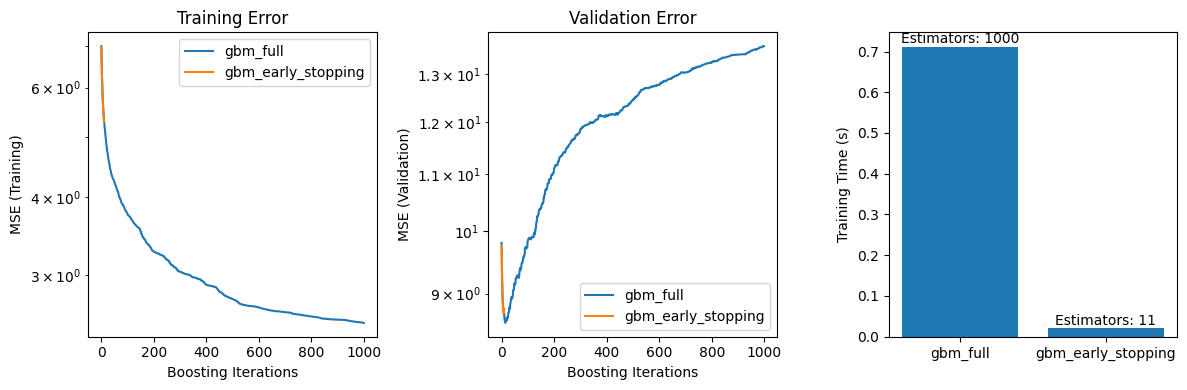

In [58]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 4))

axes[0].plot(train_errors_without, label="gbm_full")
axes[0].plot(train_errors_with, label="gbm_early_stopping")
axes[0].set_xlabel("Boosting Iterations")
axes[0].set_ylabel("MSE (Training)")
axes[0].set_yscale("log")
axes[0].legend()
axes[0].set_title("Training Error")

axes[1].plot(val_errors_without, label="gbm_full")
axes[1].plot(val_errors_with, label="gbm_early_stopping")
axes[1].set_xlabel("Boosting Iterations")
axes[1].set_ylabel("MSE (Validation)")
axes[1].set_yscale("log")
axes[1].legend()
axes[1].set_title("Validation Error")

training_times = [training_time_full, training_time_early_stopping]
labels = ["gbm_full", "gbm_early_stopping"]
bars = axes[2].bar(labels, training_times)
axes[2].set_ylabel("Training Time (s)")

for bar, n_estimators in zip(bars, [n_estimators_full, estimators_early_stopping]):
    height = bar.get_height()
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.001,
        f"Estimators: {n_estimators}",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

### Results

Here we calculate the RMSE as our loss metric to see how well our final models did.

In [59]:
test_rmse_full = mean_squared_error(y_val, pred_y_full) ** (1 / 2)
test_rmse_early_stopping = mean_squared_error(y_val, pred_y_early_stopping) ** (1 / 2)

print('Root mean Square error (full): {:.5f}'.format(test_rmse_full))
print('Root mean Square error (early stopping): {:.5f}'.format(test_rmse_early_stopping))

Root mean Square error (full): 3.69207
Root mean Square error (early stopping): 2.96236


Looking at the graph, we can see that the number of estimators and RMSE early stopping ended at is similar to the number of estimators and RMSE cross-validation came to: 

Cross Validation:
Best Parameters: {'n_estimators': 10, 'max_depth': 5, 'learning_rate': np.float64(0.11)}
Best Model RMSE: 3.0786296253198904

Early Stopping:
n_estimators = 11
Root mean Square error (early stopping): 2.96236